In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import plotly.express as pe

In [2]:
df = pd.read_json('script-bag-of-words.json')
df.head()

,episodeAlt,seasonNum,episodeNum,episodeTitle,text
0,S1E1,1,1,Winter Is Coming,"[{'text': 'Easy, boy.', 'name': 'Will'}, {'tex..."
1,S1E2,1,2,The Kingsroad,"[{'text': 'And You child... drink, eat. need t..."
2,S1E3,1,3,Lord Snow,[{'text': 'Council. Grand Lord Maester Pycelle...
3,S1E4,1,4,"Cripples, Bastards, and Broken Things",[{'text': 'Lord's The again. been dreaming lit...
4,S1E5,1,5,The Wolf and the Lion,[{'text': 'Does Hugh Ser any capital? family h...


In [3]:
df.tail()

,episodeAlt,seasonNum,episodeNum,episodeTitle,text
68,S8E2,8,2,A Knight of the Seven Kingdoms,"[{'name': 'Daenerys Targaryen', 'text': 'About..."
69,S8E3,8,3,The Long Night,"[{'name': 'Northman #1', 'text': 'Oi!'}, {'nam..."
70,S8E4,8,4,The Last of the Starks,"[{'name': 'Jon Snow', 'text': 'And Everyone It..."
71,S8E5,8,5,The Bells,"[{'name': 'Lord Varys', 'text': 'And? Come Not..."
72,S8E6,8,6,The Iron Throne,"[{'name': 'Tyrion Lannister', 'text': 'I'll fi..."


In [15]:
dialouge = {}
for index, row in df.iterrows():
    for item in row['text']:
        if item['name'] in dialouge:
            # append
            dialouge[item['name']] = dialouge[item['name']] + item['text']
        else:
            # create character
            dialouge[item['name']] = item['text'] + " "

In [16]:
len(dialogue)

817

In [24]:
new_df = pd.DataFrame()
new_df['character'] = dialogue.keys()
new_df['words'] = dialogue.values()

new_df.iloc[:,0:3].head()

,character,words
0,Will,"Easy, boy. I've I've Wildlings a a do ever in ..."
1,Waymar Royce,One They're What a and another before d'you ea...
2,Gared,Wall. We back head should the to Our They We W...
3,Jon Snow,Father's Go on. watching. And mother. your Bra...
4,Septa Mordane,"Fine Well always. as done. work, I Quite beaut..."


In [25]:
new_df['num_words'] = new_df['words'].apply(lambda x:len(x.split()))

In [26]:
new_df = new_df.sort_values('num_words',ascending=False)

In [27]:
new_df = new_df.head(100)

In [28]:
new_df.shape

(100, 3)

In [29]:
new_df.head()

,character,words,num_words
17,Tyrion Lannister,It Mmh. Northern about girls. is say the they ...,27621
13,Cersei Lannister,And And Casterly One Rock. When about afraid. ...,15234
3,Jon Snow,Father's Go on. watching. And mother. your Bra...,12591
20,Daenerys Targaryen,We've a and anything. asked been for for guest...,12196
12,Jaime Lannister,"As I It's brother, duty feel it's much. my sho...",11728


In [30]:

from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(stop_words='english')

In [31]:
embeddings = cv.fit_transform(new_df['words']).toarray()

In [32]:
embeddings.shape

(100, 9509)

In [33]:
embeddings = embeddings.astype('float64')

In [34]:
from sklearn.manifold import TSNE

In [35]:
tsne = TSNE(n_components=2, verbose=1, random_state=123)
z = tsne.fit_transform(embeddings)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 100 samples in 0.002s...
[t-SNE] Computed neighbors for 100 samples in 2.252s...
[t-SNE] Computed conditional probabilities for sample 100 / 100
[t-SNE] Mean sigma: 15.402116
[t-SNE] KL divergence after 250 iterations with early exaggeration: 60.727528
[t-SNE] KL divergence after 1000 iterations: 0.281836


In [36]:
z.shape

(100, 2)

In [37]:
new_df['x'] = z.T[0]
new_df['y'] = z.T[1]

In [38]:
new_df

,character,words,num_words,x,y
17,Tyrion Lannister,It Mmh. Northern about girls. is say the they ...,27621,-3.874258,-4.655603
13,Cersei Lannister,And And Casterly One Rock. When about afraid. ...,15234,-3.730783,-4.430610
3,Jon Snow,Father's Go on. watching. And mother. your Bra...,12591,-3.457569,-4.450528
20,Daenerys Targaryen,We've a and anything. asked been for for guest...,12196,-3.751292,-3.706076
12,Jaime Lannister,"As I It's brother, duty feel it's much. my sho...",11728,-3.543662,-4.310897
...,...,...,...,...,...
132,Rickard Karstark,Castle I'll King North! Red The They and can c...,499,2.489235,-0.786945
112,Kevan Lannister,Tyrion. Catelyn Golden Jaime Lords River River...,492,1.544848,0.075188
57,Syrio Forel,"Tomorrow You are at be boy. here late, midday....",489,1.796494,-0.065636
365,Mace Tyrell,"From Grace, House Margaery May Reach, Tyrell Y...",483,1.450924,0.230213


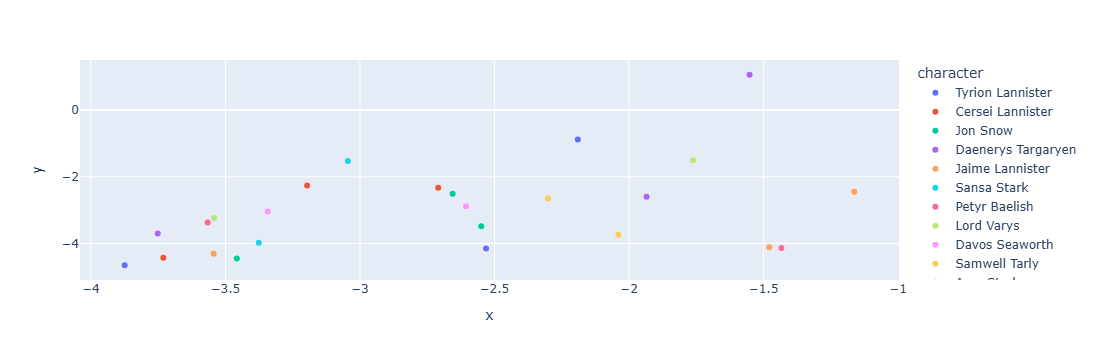

In [40]:
fig = px.scatter(new_df.head(25), x="x", y="y", color="character")
fig.show()

In [41]:
pickle.dump(
    new_df,
    open('data.pkl', 'wb')
)

In [42]:
df = pickle.load(open('data.pkl', 'rb'))

df.head()

,character,words,num_words,x,y
17,Tyrion Lannister,It Mmh. Northern about girls. is say the they ...,27621,-3.874258,-4.655603
13,Cersei Lannister,And And Casterly One Rock. When about afraid. ...,15234,-3.730783,-4.430610
3,Jon Snow,Father's Go on. watching. And mother. your Bra...,12591,-3.457569,-4.450528
20,Daenerys Targaryen,We've a and anything. asked been for for guest...,12196,-3.751292,-3.706076
12,Jaime Lannister,"As I It's brother, duty feel it's much. my sho...",11728,-3.543662,-4.310897


In [43]:
df.shape

(100, 5)